In [3]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import imblearn
import shap

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("SHAP:", shap.__version__)
print("Environment ready!")

Python: c:\Users\admin\anaconda3\envs\machine-learning-task\python.exe
Pandas: 3.0.3
Scikit-learn: 1.9.0
XGBoost: 3.4.1
Imbalanced-learn: 0.14.2
SHAP: 0.54.1
Environment ready!


![Customer Churn Analytics Dashboard](Customer%20Churn%20Analytics%20Dashboard.png)

# Customer Churn Root-Cause and Risk Scoring Analysis

## 1. Business Understanding

### 1.1 Business Problem

Customer churn occurs when customers stop using a company's services. High churn can reduce recurring revenue, increase customer acquisition costs, and weaken long-term customer relationships.

This project analyzes telecommunications customer data to identify characteristics associated with churn, develop machine learning models that estimate churn risk, and generate insights that could support evidence-based customer retention decisions.

The goal is to understand customer churn patterns, identify customers who may be at greater risk of leaving, and explore how predictive analytics can help a telecommunications business prioritize retention efforts.

### 1.2 Stakeholders

As this is an independent portfolio project, no company stakeholders have been formally engaged. The following are potential stakeholders who could benefit from the analysis in a real telecommunications business.

| Stakeholder | Role and Responsibilities | Interest in the Project |
|---|---|---|
| Customer Retention Manager | Plans and coordinates customer retention activities. | Uses churn-risk insights to prioritize retention efforts and reduce customer loss. |
| Customer Service Team | Handles customer inquiries, complaints, and service-related issues. | Identifies customers who may need support and investigates potential reasons for dissatisfaction. |
| Marketing Team | Develops customer engagement and retention campaigns. | Uses customer segments and churn patterns to inform targeted campaigns. |
| Data Science Team | Prepares data, develops models, evaluates performance, and interprets results. | Builds reliable churn prediction models and explains their predictive patterns. |
| Business Management | Sets business priorities and allocates resources. | Uses findings to inform retention strategy and resource allocation. |

These stakeholders are proposed for this project. Their involvement and the business benefits described have not been independently confirmed.

### 1.3 Project Objectives

The objectives of this project are to:

- Explore customer demographics, account information, subscribed services, contract types, tenure, and billing characteristics.
- Identify customer characteristics and service patterns associated with churn.
- Prepare the dataset for machine learning.
- Compare Random Forest and XGBoost classification models.
- Evaluate model performance using precision, recall, F1-score, and ROC-AUC.
- Generate customer-level churn probability scores and categorize customers into risk tiers.
- Interpret important model features and develop evidence-based retention recommendations.
- Document the project's limitations and potential business applications.

### 1.4 Project Scope

**Included in the project**

- Exploratory data analysis of the telecommunications customer churn dataset.
- Investigation of churn patterns across customer and service characteristics.
- Data cleaning, preprocessing, and feature preparation.
- Training and comparison of Random Forest and XGBoost models.
- Model evaluation using appropriate classification metrics.
- Generation of churn probabilities and low-, medium-, and high-risk categories.
- Interpretation of model results and formulation of potential retention recommendations.

**Excluded from the project**

- Deploying the model into a live production environment.
- Integrating with customer relationship management (CRM) systems.
- Contacting customers or implementing actual retention campaigns.
- Calculating verified financial savings without appropriate business cost and revenue data.
- Treating predictive feature importance as proof of causal relationships.

### 1.5 Business Questions

This project seeks to answer the following questions:

1. What proportion of customers in the dataset have churned?
2. Which customer characteristics, contract types, and subscribed services are associated with churn?
3. How effectively can machine learning models identify customers who churned in the observed data?
4. Which model performs better based on precision, recall, F1-score, and ROC-AUC?
5. Which customers receive high predicted churn-risk scores?
6. How could a telecommunications business use these insights to prioritize and evaluate customer retention activities?

### 1.6 Success Criteria

The project will be considered successful if it:

- Establishes a clear understanding of the dataset and observed churn patterns.
- Develops a reproducible preprocessing and modeling workflow.
- Compares Random Forest and XGBoost using a consistent evaluation strategy.
- Evaluates performance with particular attention to churn-class recall and F1-score, while also considering precision and ROC-AUC.
- Produces interpretable churn-risk scores and clearly defined risk categories.
- Identifies predictive patterns that can inform further business investigation.
- Documents limitations and avoids unsupported causal or financial claims.

The final model will be selected based on evaluation results rather than assuming that one algorithm will perform best.

### 1.7 Constraints and Assumptions

**Constraints**

- The analysis is limited to the variables and records available in the provided dataset.
- The dataset may not fully represent all telecommunications customers or current market conditions.
- Company-specific retention budgets, intervention costs, and customer lifetime value information are not available for this project.
- Class imbalance, data quality, and model assumptions may affect prediction performance.
- Predicted churn probabilities represent estimated risk, not certainty about future customer behavior.
- Model performance on historical evaluation data may differ from performance on future customers.

**Assumptions**

- The `Churn` variable represents the observed churn outcome recorded in the dataset.
- Customer demographics, account information, and service characteristics may contain useful predictive patterns.
- Historical patterns can provide a starting point for estimating churn risk, subject to appropriate validation.
- Retention recommendations generated from the analysis are proposals that would require business evaluation and testing.
- Predictive associations do not necessarily establish the causes of customer churn.

### 1.8 Expected Business Value

This project aims to demonstrate how customer analytics and machine learning can support more informed retention decisions.

Potential business benefits include:

- Understanding customer segments with higher observed churn.
- Identifying customer characteristics associated with churn.
- Prioritizing customers for further investigation using predicted risk scores.
- Supporting the design of targeted retention experiments.
- Providing a structured approach for measuring the effectiveness of future retention activities.

These benefits are potential outcomes rather than measured financial results. Actual business value would depend on model performance, the effectiveness of retention interventions, and their implementation costs.

### 1.9 Methodology

The project follows the **Cross-Industry Standard Process for Data Mining (CRISP-DM)** framework:

1. **Business Understanding:** Define the business problem, objectives, stakeholders, scope, and success criteria.
2. **Data Understanding:** Load and inspect the dataset, examine its structure, assess data quality, and explore churn patterns.
3. **Data Preparation:** Clean the data, handle missing or invalid values, encode categorical variables, and prepare the features for modeling.
4. **Modeling:** Train and compare Random Forest and XGBoost classification models.
5. **Evaluation:** Compare model performance, interpret results, and assess whether the models meet the project's success criteria.
6. **Deployment Planning:** Document how the analysis and predictions could support future retention decisions. Actual model deployment is outside the scope of this project.

# 2. Data Understanding

## 2.1 Loading the Dataset

The purpose of this phase is to understand the structure and quality of the telecommunications customer dataset before performing data cleaning, exploratory analysis, and machine learning.

In [4]:
from pathlib import Path
import pandas as pd

# Define the dataset path
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Confirm the dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found. Expected location: {DATA_PATH.resolve()}"
    )

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully!
Number of rows: 7,043
Number of columns: 21


### 2.2 Inspecting the Dataset

In [5]:
# Display the first five rows of the dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
#display the last five rows of the dataset
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [7]:
#inspect the data types of each column
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [27]:
#descriptive statistics of the dataset
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
#inspect information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [13]:
#checking for column
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [16]:
#checking dataset shape
df.shape

(7043, 21)

### 2.3 Checking Data Quality

In [17]:
#checking for columns with missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [18]:
#checking for duplicate rows in the dataset
duplicate_rows = df.duplicated().sum()
print("Duplicate rows in the dataset:")
print(duplicate_rows)

Duplicate rows in the dataset:
0


In [19]:
# Check unique customer IDs and repeated IDs

total_records = len(df)
unique_customers = df["customerID"].nunique()
repeated_ids = df["customerID"].duplicated().sum()

print("Total customer records:", total_records)
print("Unique customer IDs:", unique_customers)
print("Repeated customer IDs:", repeated_ids)

Total customer records: 7043
Unique customer IDs: 7043
Repeated customer IDs: 0


### 2.4 Understanding the Target Variable

In [20]:
# Count customers who churned and those who stayed
churn_counts = df["Churn"].value_counts()

print("Customer churn counts:")
print(churn_counts)

# Calculate percentages
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nCustomer churn percentages:")
print(churn_percentages.round(2))

Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Summary of Customer Churn Distribution

The dataset contains 7,043 customers, of whom 5,174 (73.46%) did not churn, while 1,869 (26.54%) churned. This indicates that approximately one in four customers left the telecommunications company.

The target variable, Churn, is imbalanced because the number of customers who stayed is considerably higher than the number who churned. This imbalance is important during model development and evaluation, as accuracy alone may not adequately measure the model's ability to identify customers who churn. Therefore, precision, recall, F1-score, and ROC-AUC will be considered when comparing the classification models.

### 2.5 Visualizing the Churn Distribution

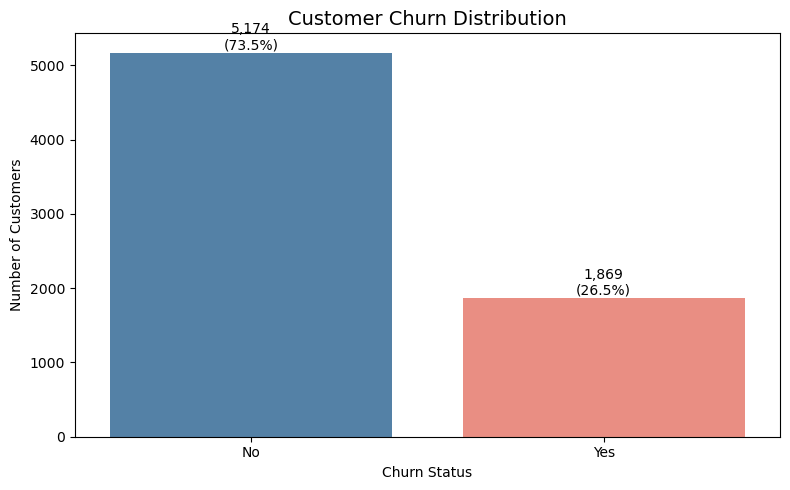

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=14)
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

# Display count and percentage above each bar
total = len(df)

for bar in ax.patches:
    count = int(bar.get_height())
    percentage = count / total * 100

    ax.annotate(
        f"{count:,}\n({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### 2.6 Statistical Summary of Numerical Variables

In [22]:
# Summary statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Interpretation of Numerical Variables

The numerical summary provides an overview of customer tenure, monthly charges, and senior citizen status.

- **SeniorCitizen:** The mean is approximately 0.162, indicating that about 16.21% of customers are classified as senior citizens, assuming the variable is encoded as 1 for senior citizens and 0 otherwise.
- **Tenure:** The average customer tenure is approximately 32.37 months, with a median of 29 months. Tenure ranges from 0 to 72 months, indicating differences in the length of customer relationships.
- **MonthlyCharges:** The average monthly charge is approximately 64.76, while the median is 70.35. Monthly charges range from 18.25 to 118.75.

These statistics provide an initial understanding of customer characteristics and billing patterns. Further analysis is needed to determine how these variables relate to churn.

In [30]:
# Summarize categorical and text columns
df.describe(include=["str", "object"])

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


### Interpretation of Categorical Variables

The categorical summary provides an overview of the customer demographics, subscribed services, contract types, payment methods, and churn status.

- **Gender:** The dataset contains two categories, Male and Female. Male is the most frequent category, with 3,555 customers.
- **Partner and Dependents:** The most frequent category for both variables is No, with 3,641 customers reporting no partner and 4,933 customers reporting no dependents.
- **PhoneService:** Most customers have phone service, with 6,361 records in the Yes category.
- **InternetService:** Fiber optic is the most frequent internet service category, appearing in 3,096 records.
- **Contract:** Month-to-month is the most frequent contract type, with 3,875 customers.
- **PaymentMethod:** Electronic check is the most frequent payment method, with 2,365 customers.
- **Churn:** No is the most frequent category, appearing in 5,174 records, consistent with the earlier churn distribution analysis.
- **TotalCharges:** Although this column represents a numeric quantity, it is currently treated as a text column. It contains 6,531 unique values, suggesting that its data type should be investigated before modeling.

These findings describe the dataset's categorical distributions. Further analysis is needed to determine how these characteristics relate to customer churn.

### 2.7 Investigating Potential Data-Quality Issues

In [31]:
# Check the data type of TotalCharges
print("TotalCharges data type:", df["TotalCharges"].dtype)

# Check for values that are blank or contain only whitespace
blank_total_charges = df["TotalCharges"].astype("str").str.strip().eq("").sum()

print("Blank TotalCharges values:", blank_total_charges)

TotalCharges data type: str
Blank TotalCharges values: 11


In [32]:
# Display records where TotalCharges is blank or whitespace-only
blank_mask = df["TotalCharges"].str.strip().eq("")

display(df.loc[blank_mask])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


### Interpretation of Blank TotalCharges Records

The investigation identified 11 records with blank or whitespace-only values in the `TotalCharges` column. All 11 customers have a tenure of zero months and a recorded churn status of `No`.

This pattern suggests that the affected records may represent newly registered customers who have not yet accumulated total charges. However, the exact reason for the blank values cannot be confirmed from the dataset alone.

During Data Preparation, the `TotalCharges` column will be converted to a numeric data type, and the blank values will be handled using an appropriate strategy. The original dataset will be preserved to maintain data integrity.

In [33]:
# Check all unique values in the target variable
print("Unique Churn values:", df["Churn"].unique())

# Check for unexpected or inconsistent target labels
print("\nChurn value counts:")
print(df["Churn"].value_counts(dropna=False))

Unique Churn values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Churn value counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### 2.8 Validation of the Target Variable

The `Churn` column contains two distinct categories: `No` and `Yes`. There are 5,174 customers labeled `No` and 1,869 customers labeled `Yes`, with no missing or unexpected target labels identified.

This confirms that the target variable is suitable for a binary classification task, subject to the remaining data preparation and validation steps. The observed class imbalance will be considered when training and evaluating the machine learning models.